

### I) Méthodes de dichotomie et de Newton


In [97]:
import numpy as np
import matplotlib.pyplot as plt

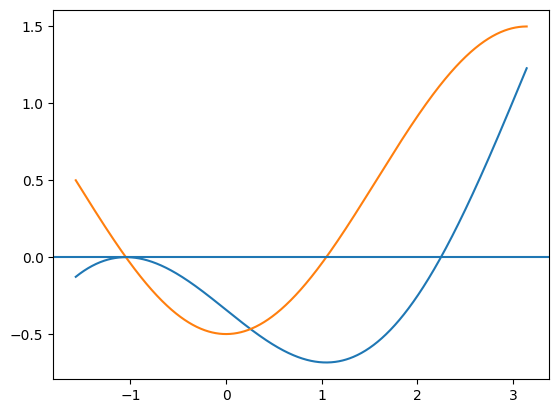

In [98]:
def g(x,args=[]):
  return x/2-np.sin(x)+np.pi/6-np.sqrt(3)/2

def dg(x,args=[]):
  return 1/2-np.cos(x)

x=np.linspace(-np.pi/2,np.pi,1000)
plt.plot(x,g(x))
plt.plot(x,dg(x))
plt.axhline(y=0)

Le premier zéro est un max local, et on ne peut donc pas utiliser la dichotomie.

3) et 4)

In [99]:
def dichotomie(f,a,b,tol,nmax,args=[]):
  fa=f(a,args)
  fb=f(b,args)
  listres=[]


  if fa*fb >=0:
    return False

  it=0

  for i in range(nmax):
    c=(a+b)/2
    fc=f(c,args)
    it+=1
    listres.append(abs(fc))
    if abs(fc)<tol:
      return c,it,f(c,args),listres
    if fa*fc<0:
      b=c
      fb=fc
    else:
      a=c
      fa=fc

  return c,it,f(c,args),listres

zero,it,fc=dichotomie(g,1,np.pi,10**(-10),1000)[0],dichotomie(g,1,np.pi,10**(-10),1000)[1],dichotomie(g,1,np.pi,10**(-10),1000)[2]

print(zero,it,fc)

2.246005589227533 29 -7.925082812221262e-11


5)

In [100]:
def newton(f,df,x0,tol,nmax,args=[]):
  listinc=[]
  x=x0
  listres=[f(x,args)]
  it=0
  res=0

  for i in range(1,nmax):
    fx=f(x,args)
    dfx=df(x,args)
    it+=1
    if dfx==0:
      return False

    dx=-fx/dfx
    x1=x+dx

    inc=abs(dx)
    res=abs(f(x1,args))

    listinc.append(inc)
    listres.append(res)

    x=x1
    if res<tol:
      return x,it,res,listinc,listres

  return x,it,res,listinc,listres

resultatxi=newton(g,dg,np.pi,10**(-10),100,args=[])
print(resultatxi)

resultateta=newton(g,dg,-np.pi/2,10**(-10),100,args=[])
print(resultateta)

(np.float64(2.2460055892984685), 4, np.float64(5.561107130347409e-13), [np.float64(0.8189131324058377), np.float64(0.0748166201337316), np.float64(0.0018561177946694145), np.float64(1.1939570858699223e-06)], [np.float64(1.2283696986087567), np.float64(0.08850921849956672), np.float64(0.002090934087671692), np.float64(1.343275278564704e-06), np.float64(5.561107130347409e-13)])
(np.float64(-1.047206078066725), 16, np.float64(3.14833714654128e-11), [np.float64(0.2556495831671762), np.float64(0.13151491157410602), np.float64(0.06745727032243043), np.float64(0.03427746069029686), np.float64(0.017294141837665644), np.float64(0.008688419811546328), np.float64(0.004354874926536443), np.float64(0.0021801457528014432), np.float64(0.0010907552717759061), np.float64(0.0005455489045041277), np.float64(0.0002728173533983582), np.float64(0.0001364194126863149), np.float64(6.821239163572757e-05), np.float64(3.4106866598943764e-05), np.float64(1.705360087659206e-05), np.float64(8.526844136196802e-06)],

/tmp/ipykernel_5504/1343547445.py:5: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.log10(res1))


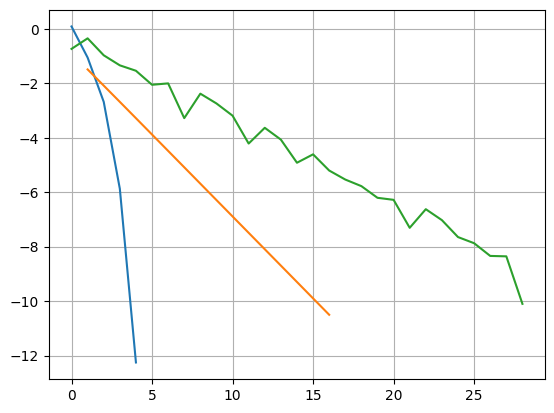

In [101]:
res0=resultatxi[4]
res1=resultateta[4]
res2=dichotomie(g,1,np.pi,10**(-10),1000)[3]
plt.plot(np.log10(res0))
plt.plot(np.log10(res1))
plt.plot(np.log10(res2))
plt.grid()

In [102]:
def fausseposition(f,a,b,tol,nmax,args=[]):
  fa=f(a,args)
  fb=f(b,args)
  listres=[abs(f((a*fb-b*fa)/(fb-fa),args))]
  it=0

  if fa*fb >=0:
    return False

  for i in range(nmax):
    if fb ==fa:
      return False
    c=(a*fb-b*fa)/(fb-fa)
    fc=f(c,args)
    it+=1
    listres.append(abs(fc))

    if abs(fc)<tol:
      return c,it,f(c,args),listres
    if fa*fc<0:
      b=c
      fb=fc
    else:
      a=c
      fa=fc

  return c,it,f(c,args),listres

def secante(f,x0,x1,tol,nmax,args=[]):
  listinc=[]
  xav,xap=x0,x1
  fav,fap=f(xav,args),f(xap,args)
  it=0
  res=abs(f(xap-fap*(xap-xav)/(fap-fav),args))
  listres=[res]
  for i in range(1,nmax):

    if fap-fav==0:
      return x2,it,res,listinc,listres
    it+=1

    x2=xap-fap*(xap-xav)/(fap-fav)

    inc=abs(x2-xap)
    res=abs(f(x2,args))

    listinc.append(inc)
    listres.append(res)

    xav,fav=xap,fap
    xap,fap=x2,f(x2,args)
    if res<tol:
      return x2,it,res,listinc,listres

  return xap,it,res,listinc,listres

/tmp/ipykernel_5504/3125512187.py:12: RuntimeWarning: divide by zero encountered in log10
  plt.plot(np.log10(resnewton),label='Newton')


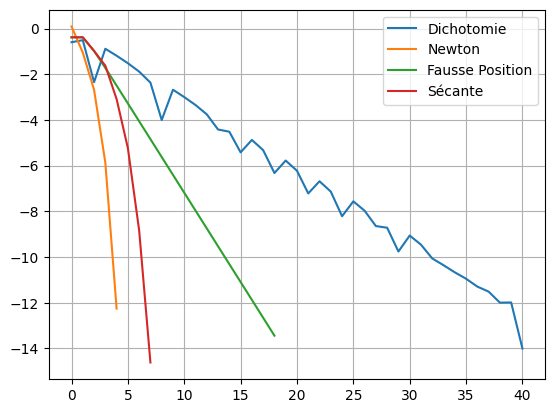

In [103]:
nmax=100
a,b=1,3
x0=np.pi
tol=10**(-13)

resdich=dichotomie(g,a,b,tol,nmax)[3]
resnewton=newton(g,dg,x0,tol,nmax,args=[])[4]
resfaupo=fausseposition(g,a,b,tol,nmax,args=[])[3]
ressecante=secante(g,a,b,tol,nmax,args=[])[4]

plt.plot(np.log10(resdich),label='Dichotomie')
plt.plot(np.log10(resnewton),label='Newton')
plt.plot(np.log10(resfaupo),label='Fausse Position')
plt.plot(np.log10(ressecante),label='Sécante')
plt.legend()
plt.grid()

### 2) Bassins de convergence de la méthode de Newton Raphson

Les trois racines de l'unité sont
$\begin{align}
z_0&=1\quad &x_0=\left(1,0\right)\\
z_1&=e^{\frac{2i\pi}{3}}&\quad x=\left(-\frac{1}{2},\frac{\sqrt{3}}{2}\right)\\
z_2&=e^{\frac{-2i\pi}{3}}&\quad x=\left(-\frac{1}{2},\frac{-\sqrt{3}}{2}\right)
\end{align}$

In [113]:
def f(x):
  return np.array([x[0]**3-3*x[1]**2*x[0]-1,3*x[0]**2*x[1]-x[1]**3])

def df(x):
  return np.array([[3*x[0]**2-3*x[1]**2,-6*x[1]*x[0]],[6*x[1]*x[0],3*x[0]**2-3*x[1]**2]])